# BIOT 6900 · Module 6, Part 3 — Graded Assignment: PRS Portability on Real Data
## Disease: Pancreatic ductal adenocarcinoma (PDAC) · Score: PGS000725

**Author:** Deepthi Dineshkumar

This notebook runs the full PRS portability workflow on **real 1000 Genomes phase 3 genotypes (GRCh37, 2,504 people, 5 super-populations)** with a **published pancreatic cancer score from the PGS Catalog, PGS000725** (Jia et al., *JNCI Cancer Spectrum* 2020; 22 genome-wide significant variants, beta weights, developed in 100% European-ancestry GWAS). It continues the PDAC theme of my earlier BIOT6900 modules (CPTAC-PDAC target discovery).

Steps: harmonize alleles, compute the PRS, and evaluate discrimination, calibration, and portability across ancestry groups.


### Data (built from public sources)

The four input files were built with `build_inputs.sh` and `make_data.py` (both in this folder). To rebuild:

```bash
bash build_inputs.sh PGS000725      # downloads the score + 1000G genotypes, then runs make_data.py
```

| File | Columns | Source |
|---|---|---|
| `genotypes.csv` | `sample` + one column per variant, rows = people | **real**: 1000G phase 3, dosages 0/1/2 counting the **ALT** allele |
| `variants.csv` | `variant`, `ref`, `alt` | **real**: REF/ALT from the 1000G VCFs (GRCh37) |
| `score.csv` | `variant`, `effect_allele`, `other_allele`, `weight` | **real**: PGS000725 harmonized GRCh37 scoring file, alleles as published |
| `meta.csv` | `sample`, `ancestry`, `age`, `phenotype` | ancestry **real** (1000G super-population); age and phenotype **simulated** |

> ⚠️ **The phenotype is simulated.** 1000 Genomes has no disease labels. The PRS and its distribution across ancestries are computed on real inputs; AUC and calibration use a simulated label and are illustrative only.

> **Simulation design (see `data/SIMULATION_NOTES.txt`).** Age ~ N(65, 8). Case status comes from a logistic model with OR 1.5 per SD of genetic liability (in line with published PDAC PRS effect sizes) plus an age term. Liability = ρ × (PRS centred within group) + noise, where ρ is the score's assumed tagging efficiency: EUR 1.00, AMR 0.79, SAS 0.79, EAS 0.71, AFR 0.47 (from the PRS accuracy losses in Martin et al., *Nat Genet* 2019). Case fraction is fixed at 30% in every group, so **true risk is equal across ancestries by construction**. The AUC drop outside EUR is therefore partly built into the simulation; the PRS distribution shift and the cutoff results are not.

> **Proof of real data.** Section 2 prints a fingerprint (file checksums, counts), which is pasted into the report.


## 0. Setup

In [1]:
import os, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
from sklearn.metrics import roc_auc_score
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score, StratifiedKFold

NU_RED, NU_COOL, NU_GREY = "#C8102E", "#1E2028", "#6E7178"
POP_COLORS = {"EUR":"#1E2028","AFR":"#C8102E","EAS":"#6E7178","SAS":"#A4804A","AMR":"#9AA0A6"}
rng = np.random.default_rng(6900)
os.makedirs("figures", exist_ok=True)

USE_DEMO = False     # <-- prototyping only. MUST be False for your graded submission.

## 1. Load the data  *(provided, do not edit)*

Strict loader: with `USE_DEMO = False` it requires all four real files and refuses to run otherwise. The demo path is clearly labelled and is never acceptable for grading.

In [2]:
BASES = np.array(list("ACGT"))
def _make_demo_cohort(seed=6900):
    r = np.random.default_rng(seed)
    pops = {"EUR":(600,0.92,0.05,0.14),"AFR":(600,0.40,0.15,0.22),"EAS":(500,0.58,0.12,0.09),
            "SAS":(500,0.66,0.09,0.09),"AMR":(500,0.55,0.07,0.11)}   # n, tag-rho, drift, APOE freq
    M = 80
    b = r.normal(0, 0.15, M); b[0] = 1.3
    w_true = b * 0.92
    base = r.uniform(0.15, 0.5, M)
    Gt, Gc, anc, ages = [], [], [], []
    for pop,(n,rho,drift,apoe) in pops.items():
        f = np.clip(base + r.normal(0,drift,M), 0.03, 0.97); f[0] = apoe; thr = norm.ppf(f)
        gc = np.zeros((n,M)); gt = np.zeros((n,M))
        for _ in range(2):
            L = r.normal(size=(n,M)); Z = r.normal(size=(n,M))
            gc += (L<thr); gt += ((rho*L + np.sqrt(1-rho**2)*Z) < thr)
        Gt.append(gt); Gc.append(gc); anc += [pop]*n; ages.append(r.normal(60,8,n))
    Gt = np.vstack(Gt); Gc = np.vstack(Gc); anc = np.array(anc); age = np.concatenate(ages)
    lin = Gc @ b + 0.03*(age-60); b0 = np.log(0.30/0.70) - lin.mean()
    y = (r.uniform(size=len(lin)) < 1/(1+np.exp(-(b0+lin)))).astype(int)
    variants = [f"rs_tag_{i:03d}" for i in range(M)]
    # real nucleotides: pick ref != alt; dosages count ALT
    ref = r.choice(BASES, M); alt = np.array([r.choice(BASES[BASES!=ref[i]]) for i in range(M)])
    geno = pd.DataFrame(Gt, columns=variants)
    vtab = pd.DataFrame({"variant":variants, "ref":ref, "alt":alt})
    # 25% of rows report the REF allele as effect allele, with the weight's sign reversed
    report_ref = r.random(M) < 0.25
    eff = np.where(report_ref, ref, alt); oth = np.where(report_ref, alt, ref)
    wrep = np.where(report_ref, -w_true, w_true)
    score = pd.DataFrame({"variant":variants, "effect_allele":eff, "other_allele":oth, "weight":wrep})
    meta  = pd.DataFrame({"ancestry":anc, "age":age, "phenotype":y})
    return geno, vtab, score, meta

REAL_FILES = ["genotypes.csv","variants.csv","score.csv","meta.csv"]
def _sha8(path):
    h = hashlib.sha256(open(path,"rb").read()).hexdigest()[:8]
    return h

def load_data(path="data"):
    present = [f for f in REAL_FILES if os.path.exists(os.path.join(path,f))]
    if not USE_DEMO:
        missing = [f for f in REAL_FILES if f not in present]
        if missing:
            raise FileNotFoundError(
                "GRADED RUN requires all four files in ./%s/ . Missing: %s .  "
                "Set USE_DEMO=True ONLY to prototype on synthetic data; it must be False for submission."
                % (path, ", ".join(missing)))
        geno=pd.read_csv(os.path.join(path,"genotypes.csv"))
        vtab=pd.read_csv(os.path.join(path,"variants.csv"))
        score=pd.read_csv(os.path.join(path,"score.csv"))
        meta=pd.read_csv(os.path.join(path,"meta.csv"))
        info={"source":"REAL","hashes":{f:_sha8(os.path.join(path,f)) for f in REAL_FILES}}
        print("="*64); print("  RUNNING ON REAL DATA"); print("="*64)
    else:
        print("="*64); print("  USE_DEMO=True  ->  SYNTHETIC demo cohort  (NOT FOR GRADING)"); print("="*64)
        geno,vtab,score,meta=_make_demo_cohort(); info={"source":"DEMO","hashes":None}
    return geno, vtab, score, meta, info

geno, variants, score, meta, info = load_data()

  RUNNING ON REAL DATA


## 2. Proof of real data 

In [3]:
print("source      :", info["source"])
print("people      :", len(meta))
print("score size  :", len(score), "variants")
print("by ancestry :", dict(meta["ancestry"].value_counts()))
if info["source"] == "REAL":
    for f,h in info["hashes"].items():
        print(f"  {f}: sha256 {h}")
else:
    print("  DEMO cohort - not acceptable for your graded submission")

source      : REAL
people      : 2504
score size  : 22 variants
by ancestry : {'AFR': np.int64(661), 'EAS': np.int64(504), 'EUR': np.int64(503), 'SAS': np.int64(489), 'AMR': np.int64(347)}
  genotypes.csv: sha256 bbd9bb17
  variants.csv: sha256 2a0cf215
  score.csv: sha256 a8e3a9d6
  meta.csv: sha256 b582b129


In [4]:
# Simulation settings used to build meta.csv 
notes = os.path.join("data", "SIMULATION_NOTES.txt")
print(open(notes).read() if os.path.exists(notes) else "SIMULATION_NOTES.txt not found")

Score: PGS000725 (PGS Catalog, GRCh37 harmonized) - 22 variants; 22 found in 1000G phase 3
Genotypes: 1000 Genomes phase 3 (GRCh37), 2504 people, biallelic SNPs, dosage = ALT count
Ancestry: 1000G super-population labels
SIMULATED: age ~ N(65, 8) clipped 40-90; phenotype from logistic model:
  logit = b0[group] + log(1.5)*liability + 0.06*(age-65)
  liability = rho[group]*PRS_within_group + sqrt(1-rho^2)*noise   (PRS in EUR-SD units)
  rho = {'EUR': 1.0, 'AMR': 0.79, 'SAS': 0.79, 'EAS': 0.71, 'AFR': 0.47}  (tagging efficiency; Martin et al. 2019)
  b0[group] set so case fraction = 0.3 in every group (equal true risk across groups)
Seed: 6900



## 3.1 Harmonize alleles: keep / flip / drop

For each variant, compare the score's `effect_allele` with that variant's REF and ALT (all uppercased first):
- equals **ALT** → keep the dosage and weight as is,
- equals **REF** → flip the dosage (`2 − dosage`),
- equals **neither** → drop the variant.

I also report score variants that are **absent from the panel entirely**, which separates "dropped for allele mismatch" from "not in the data", and flag **palindromic** SNPs (A/T, C/G), where an allele match cannot rule out a strand flip.

In [5]:
shared = [v for v in score["variant"] if v in geno.columns]
not_found = [v for v in score["variant"] if v not in geno.columns]
G = geno[shared].to_numpy(dtype=float).copy()
s = score.set_index("variant").loc[shared]
v = variants.set_index("variant").loc[shared]
eff = np.char.upper(s["effect_allele"].to_numpy().astype(str))
ref = np.char.upper(v["ref"].to_numpy().astype(str)); alt = np.char.upper(v["alt"].to_numpy().astype(str))
w = s["weight"].to_numpy()

keep = eff == alt
flip = (eff == ref) & ~keep
drop = ~(keep | flip)

palin = np.array([{r, a} in ({"A","T"}, {"C","G"}) for r, a in zip(ref, alt)])

G[:, flip] = 2 - G[:, flip]
used_names = np.array(shared)[~drop]
G = G[:, ~drop]; w = w[~drop]

print(f"score variants        : {len(score)}")
print(f"not found in panel    : {len(not_found)}  {not_found}")
print(f"used {int((keep|flip).sum())}  flipped {int(flip.sum())}  dropped {int(drop.sum())}  (allele mismatch)")
print(f"palindromic (A/T, C/G) among used: {int((palin & ~drop).sum())}")

score variants        : 22
not found in panel    : 0  []
used 22  flipped 12  dropped 0  (allele mismatch)
palindromic (A/T, C/G) among used: 3


## 3.2 Compute the PRS

In [6]:
prs = G @ w
prs_z = (prs - prs.mean()) / prs.std()
meta["prs"] = prs_z
print("PRS computed for", len(prs_z), "people using", G.shape[1], "variants")

# sanity check: with correct alignment, cases should score higher than controls
print("mean PRS  cases:", round(meta.loc[meta.phenotype==1, "prs"].mean(), 3),
      "  controls:", round(meta.loc[meta.phenotype==0, "prs"].mean(), 3))

PRS computed for 2504 people using 22 variants
mean PRS  cases: 0.174   controls: -0.073


## 3.3 Distribution shift and a single cutoff

Plot the PRS distribution per ancestry, then show what one fixed cutoff does: take the whole-cohort top-10% PRS value and report the fraction of each ancestry group above it.

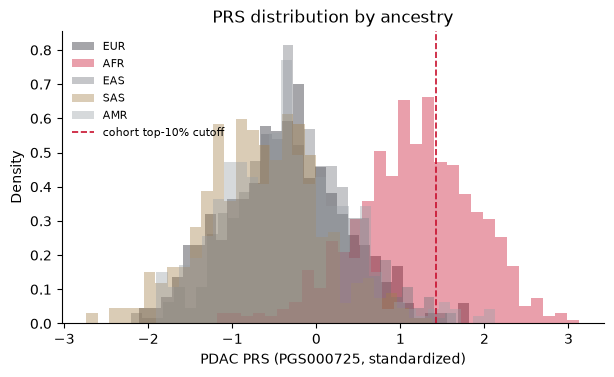

Cohort-wide top-10% cutoff = 1.427 (expected 10% in every group if the score were portable)
ancestry   n  mean_PRS  SD_PRS  pct_above_cutoff
     EUR 503    -0.358   0.718               1.2
     AFR 661     1.164   0.717              35.4
     EAS 504    -0.268   0.664               0.6
     SAS 489    -0.658   0.694               0.0
     AMR 347    -0.382   0.742               2.3


In [7]:
fig, ax = plt.subplots(figsize=(7,3.8))
for pop, c in POP_COLORS.items():
    sub = meta.loc[meta.ancestry==pop, "prs"]
    ax.hist(sub, bins=30, density=True, alpha=0.4, color=c, label=pop)
cutoff = np.quantile(meta["prs"], 0.90)
ax.axvline(cutoff, color=NU_RED, ls="--", lw=1.2, label="cohort top-10% cutoff")
ax.set_xlabel("PDAC PRS (PGS000725, standardized)"); ax.set_ylabel("Density"); ax.legend(frameon=False, loc="upper left", fontsize=8)
ax.set_title("PRS distribution by ancestry")
for sp in ("top","right"): ax.spines[sp].set_visible(False)
plt.savefig("figures/prs_distribution_by_ancestry.png", dpi=200, bbox_inches="tight")
plt.show()

rows = []
for pop in POP_COLORS:
    sub = meta.loc[meta.ancestry==pop, "prs"]
    rows.append({"ancestry": pop, "n": len(sub), "mean_PRS": round(sub.mean(), 3),
                 "SD_PRS": round(sub.std(), 3), "pct_above_cutoff": round(100*(sub > cutoff).mean(), 1)})
cut_table = pd.DataFrame(rows)
print(f"Cohort-wide top-10% cutoff = {cutoff:.3f} (expected 10% in every group if the score were portable)")
print(cut_table.to_string(index=False))
cut_table.to_csv("figures/cutoff_by_ancestry.csv", index=False)

## 3.4 Discrimination by ancestry

In [8]:
y = meta["phenotype"].to_numpy()
prs_arr = meta["prs"].to_numpy()

def boot_auc(y, x, n=1000, seed=6900):
    r = np.random.default_rng(seed); vals = []
    for _ in range(n):
        i = r.integers(0, len(y), len(y))
        if y[i].min() != y[i].max(): vals.append(roc_auc_score(y[i], x[i]))
    return np.percentile(vals, [2.5, 97.5])

lo, hi = boot_auc(y, prs_arr)
print(f"Overall AUC: {roc_auc_score(y, prs_arr):.3f}  (95% CI {lo:.3f}-{hi:.3f})")
auc_rows = []
for pop in POP_COLORS:
    m = (meta.ancestry==pop).to_numpy()
    a = roc_auc_score(y[m], prs_arr[m]); lo, hi = boot_auc(y[m], prs_arr[m])
    auc_rows.append({"ancestry": pop, "n": int(m.sum()), "cases": int(y[m].sum()),
                     "AUC": round(a, 3), "CI_low": round(lo, 3), "CI_high": round(hi, 3)})
    print(f"  {pop}: AUC = {a:.3f}  (95% CI {lo:.3f}-{hi:.3f})")
pd.DataFrame(auc_rows).to_csv("figures/auc_by_ancestry.csv", index=False)

Overall AUC: 0.574  (95% CI 0.548-0.597)
  EUR: AUC = 0.619  (95% CI 0.566-0.672)
  AFR: AUC = 0.549  (95% CI 0.503-0.597)
  EAS: AUC = 0.589  (95% CI 0.533-0.638)
  SAS: AUC = 0.595  (95% CI 0.546-0.650)
  AMR: AUC = 0.653  (95% CI 0.593-0.710)


## 3.5 Calibration by ancestry

Fit the risk model **in EUR only**, apply it to everyone, and draw one calibration curve per ancestry. A model honest in EUR is often not honest elsewhere. The helper is provided.

In [9]:
def calibration_points(y, p, bins=5):
    edges = np.quantile(p, np.linspace(0,1,bins+1)); edges[-1]+=1e-9
    idx = np.clip(np.digitize(p, edges)-1, 0, bins-1)
    xs, ys = [], []
    for b in range(bins):
        m = idx==b
        if m.sum() > 5: xs.append(p[m].mean()); ys.append(y[m].mean())
    return np.array(xs), np.array(ys)

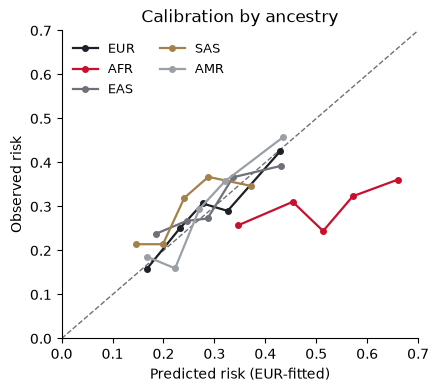

ancestry  mean_predicted  observed  pred_minus_obs
     EUR           0.286     0.286           0.000
     AFR           0.510     0.300           0.210
     EAS           0.297     0.308          -0.011
     SAS           0.249     0.292          -0.043
     AMR           0.284     0.291          -0.007


In [10]:
prs_z = meta["prs"].to_numpy(); y = meta["phenotype"].to_numpy()
eur = (meta.ancestry=="EUR").to_numpy()

model = LogisticRegression().fit(prs_z[eur].reshape(-1,1), y[eur])
p_hat = model.predict_proba(prs_z.reshape(-1,1))[:,1]

fig, ax = plt.subplots(figsize=(4.6,4.0))
ax.plot([0,1],[0,1], ls="--", color=NU_GREY, lw=1)
for pop, c in POP_COLORS.items():
    m = (meta.ancestry==pop).to_numpy()
    xs, ys = calibration_points(y[m], p_hat[m])
    ax.plot(xs, ys, marker="o", ms=4, color=c, lw=1.6, label=pop)
ax.set_xlim(0, 0.7); ax.set_ylim(0, 0.7)
ax.set_xlabel("Predicted risk (EUR-fitted)"); ax.set_ylabel("Observed risk")
ax.set_title("Calibration by ancestry"); ax.legend(frameon=False, ncol=2, fontsize=9)
for sp in ("top","right"): ax.spines[sp].set_visible(False)
plt.savefig("figures/calibration_by_ancestry.png", dpi=200, bbox_inches="tight")
plt.show()

# calibration-in-the-large: mean predicted vs observed risk per group
cal = pd.DataFrame([{"ancestry": pop,
                     "mean_predicted": round(p_hat[(meta.ancestry==pop).to_numpy()].mean(), 3),
                     "observed": round(y[(meta.ancestry==pop).to_numpy()].mean(), 3)} for pop in POP_COLORS])
cal["pred_minus_obs"] = (cal.mean_predicted - cal.observed).round(3)
print(cal.to_string(index=False))

## 3.6 Does the PRS add to age alone?

In [11]:
age_z = ((meta["age"]-meta["age"].mean())/meta["age"].std()).to_numpy()
y = meta["phenotype"].to_numpy()
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=6900)   # shuffled: rows are grouped by ancestry
X_age  = age_z.reshape(-1,1)
X_both = np.column_stack([age_z, meta["prs"].to_numpy()])
auc_age     = cross_val_score(LogisticRegression(), X_age,  y, cv=cv, scoring="roc_auc").mean()
auc_age_prs = cross_val_score(LogisticRegression(), X_both, y, cv=cv, scoring="roc_auc").mean()
print(f"AUC age only:  {auc_age:.3f}")
print(f"AUC age + PRS: {auc_age_prs:.3f}")
print(f"Incremental AUC from PRS: {auc_age_prs - auc_age:+.3f}")

# same comparison within each ancestry group
for pop in POP_COLORS:
    m = (meta.ancestry==pop).to_numpy()
    a1 = cross_val_score(LogisticRegression(), X_age[m],  y[m], cv=cv, scoring="roc_auc").mean()
    a2 = cross_val_score(LogisticRegression(), X_both[m], y[m], cv=cv, scoring="roc_auc").mean()
    print(f"  {pop}: age {a1:.3f}  age+PRS {a2:.3f}  gain {a2-a1:+.3f}")

AUC age only:  0.629
AUC age + PRS: 0.649
Incremental AUC from PRS: +0.020
  EUR: age 0.648  age+PRS 0.691  gain +0.043
  AFR: age 0.625  age+PRS 0.637  gain +0.012
  EAS: age 0.647  age+PRS 0.664  gain +0.018
  SAS: age 0.609  age+PRS 0.640  gain +0.030
  AMR: age 0.610  age+PRS 0.677  gain +0.066


## 3.7 Interpretation  *(write-up, the 40%)*

Answered in the 3 to 4 page report, which includes the Section 2 proof-of-data block.

1. **Portability.** Why does the European-derived PDAC score (PGS000725) lose accuracy in other ancestries? Point to LD and allele-frequency differences.
2. **One threshold, many groups.** Using the Section 3.3 table, is a single top-10% cutoff fair? What happens if a clinic applies it unchanged?
3. **Discrimination vs calibration.** What did each tell me (3.4, 3.5), and where did they disagree?
4. **Clinical utility and limits.** Where could a PDAC PRS help (e.g. enriching surveillance in high-risk groups such as new-onset diabetes or family history), where should it not be used (population screening for a low-prevalence cancer), and what would be needed before deployment? The phenotype here is simulated; name the real data needed to validate (e.g. PanScan/PanC4 case-control data, UK Biobank, All of Us, multi-ancestry cohorts).
5. **Artifact versus biology.** Which results in this notebook were built into the simulation (the ρ tagging-efficiency assumption, equal true risk across groups), and which come from the real genotypes (the PRS distribution shift and the cutoff fractions)? Why does a low AUC here not show that these loci are irrelevant to PDAC in non-European people?

## Submit

- Confirm `USE_DEMO = False` and that Section 2 shows **source: REAL** with file checksums.
- **Kernel → Restart & Run All.**
- Commit the notebook, `figures/`, `build_inputs.sh`, `make_data.py`, `data/SIMULATION_NOTES.txt` and a README to the `biot6900` repo (`module6/`); push; post the repo link on Canvas.